# ConstructionSite 10k: dataset analysis

Explores the whole dataset (train and test) before any modelling.

**What it covers**

1. Splits and columns
2. Violations per rule, and how they compare with the paper's counts
3. Class imbalance and which rules occur together
4. Image attributes (illumination, camera distance, view, quality of info)
5. Caption length
6. Image resolution
7. Bounding boxes (violations and grounding objects)
8. Violation reason text
9. Data-quality checks
10. Example images with violation boxes drawn

**How to run** (once, in the project's `venv-vlm`):

```bat
pip install matplotlib notebook
set HF_HOME=E:\Mayank\Nirma\Projects\construction-safety-vlm\hf_cache
jupyter notebook
```

Every number in this notebook is computed from the downloaded data. Nothing is
typed in by hand except the paper's counts in `src/rules.py`, which are used
only for comparison. No GPU is needed.

In [2]:
import io
import json
import os
import re
import sys
import textwrap
from collections import Counter
from pathlib import Path

# Project root = the folder that contains src/ (works from notebooks/ or the root).
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
assert (ROOT / "src").exists(), f"Cannot find src/ next to {Path.cwd()}"
sys.path.insert(0, str(ROOT))

# Must be set BEFORE importing datasets, so the copy on E: is used.
os.environ.setdefault("HF_HOME", str(ROOT / "hf_cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import Image as HFImage
from datasets import load_dataset
from matplotlib.patches import Rectangle
from PIL import Image

from src.data import has_violation, violation_reason
from src.rules import DATASET_ID, EXPECTED_VIOLATIONS, RULE_IDS, RULE_NAMES, RULES

OUT = ROOT / "outputs" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

ATTRIBUTES = ["illumination", "camera_distance", "view", "quality_of_info"]
GROUNDING = ["excavator", "rebar", "worker_with_white_hard_hat"]

# Chart style: train is always blue, test is always orange.
SPLIT_COLOR = {"train": "#2a78d6", "test": "#eb6834"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
})
pd.set_option("display.max_colwidth", 120)


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")


print("Project root:", ROOT)
print("HF_HOME     :", os.environ["HF_HOME"])

e:\Mayank\Nirma\Projects\construction-safety-vlm\venv-vlm\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: e:\Mayank\Nirma\Projects\construction-safety-vlm
HF_HOME     : e:\Mayank\Nirma\Projects\construction-safety-vlm\hf_cache


## Load the dataset

In [3]:
ds = load_dataset(DATASET_ID)
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'image_id', 'image_caption', 'illumination', 'camera_distance', 'view', 'quality_of_info', 'rule_1_violation', 'rule_2_violation', 'rule_3_violation', 'rule_4_violation', 'excavator', 'rebar', 'worker_with_white_hard_hat'],
        num_rows: 7009
    })
    test: Dataset({
        features: ['image', 'image_id', 'image_caption', 'illumination', 'camera_distance', 'view', 'quality_of_info', 'rule_1_violation', 'rule_2_violation', 'rule_3_violation', 'rule_4_violation', 'excavator', 'rebar', 'worker_with_white_hard_hat'],
        num_rows: 3004
    })
})

In [4]:
first = next(iter(ds.values()))
pd.DataFrame({"column": list(first.features), "type": [str(f) for f in first.features.values()]})

,column,type
0,image,"Image(mode=None, decode=True)"
1,image_id,Value('string')
2,image_caption,Value('string')
3,illumination,Value('string')
4,camera_distance,Value('string')
5,view,Value('string')
6,quality_of_info,Value('string')
7,rule_1_violation,"{'bounding_box': List(List(Value('float64'))), 'reason': Value('string')}"
8,rule_2_violation,"{'bounding_box': List(List(Value('float64'))), 'reason': Value('string')}"
9,rule_3_violation,"{'bounding_box': List(List(Value('float64'))), 'reason': Value('string')}"


## Build one table for the whole dataset

One row per image, without decoding the pictures (fast). A second table holds
every bounding box. All later sections read from these two tables.

In [5]:
def boxes_of(value):
    """Return a list of [x1, y1, x2, y2] boxes from any of the forms the
    dataset uses: None, a dict with 'bounding_box', a list of boxes, one flat
    box, or a JSON string of any of these."""
    if value is None:
        return []
    if isinstance(value, str):
        try:
            return boxes_of(json.loads(value))
        except (ValueError, TypeError):
            return []
    if isinstance(value, dict):
        return boxes_of(value.get("bounding_box"))
    if isinstance(value, (list, tuple)):
        if len(value) == 4 and all(isinstance(x, (int, float)) for x in value):
            return [list(map(float, value))]
        out = []
        for b in value:
            out.extend(boxes_of(b))
        return out
    return []


rows, box_rows = [], []
for split, d in ds.items():
    meta = d.remove_columns([c for c in d.column_names if c == "image"])
    for idx, ex in enumerate(meta):
        row = {
            "split": split,
            "idx": idx,
            "image_id": str(ex["image_id"]),
            "caption": ex.get("image_caption") or "",
        }
        for a in ATTRIBUTES:
            row[a] = ex.get(a)
        for k in RULE_IDS:
            v = ex.get(f"rule_{k}_violation")
            b = boxes_of(v)
            row[f"rule_{k}"] = has_violation(v)
            row[f"rule_{k}_boxes"] = len(b)
            row[f"rule_{k}_reason"] = violation_reason(v)
            for box in b:
                box_rows.append([split, row["image_id"], "violation", f"rule_{k}", *box])
        for g in GROUNDING:
            b = boxes_of(ex.get(g))
            row[f"n_{g}"] = len(b)
            for box in b:
                box_rows.append([split, row["image_id"], "object", g, *box])
        rows.append(row)

df = pd.DataFrame(rows)
boxes = pd.DataFrame(box_rows, columns=["split", "image_id", "kind", "label", "x1", "y1", "x2", "y2"])
RULE_COLS = [f"rule_{k}" for k in RULE_IDS]
df["n_rules_violated"] = df[RULE_COLS].sum(axis=1)
df["any_violation"] = df["n_rules_violated"] > 0
SPLITS = [s for s in ["train", "test"] if s in set(df["split"])] + sorted(set(df["split"]) - {"train", "test"})

print(f"{len(df):,} images, {len(boxes):,} bounding boxes")
df.head(3)

10,013 images, 11,138 bounding boxes


,split,idx,image_id,caption,illumination,camera_distance,view,quality_of_info,rule_1,rule_1_boxes,...,rule_3_boxes,rule_3_reason,rule_4,rule_4_boxes,rule_4_reason,n_excavator,n_rebar,n_worker_with_white_hard_hat,n_rules_violated,any_violation
0,train,0,0004850,"The image shows three workers with yellow hard hats, engaged in tasks related to reinforcing steel bars at a constru...",normal lighting,short distance,elevation view,poor info,False,0,...,0,,True,1,The worker in the upper left is at the rear of the excavator.,1,0,0,1,True
1,train,1,0004851,"The excavator is positioned in the center, actively digging into the earth with its bucket. The operator is visible ...",normal lighting,short distance,elevation view,poor info,False,0,...,1,The excavation edge in the background is not protected.,False,0,,1,0,0,1,True
2,train,2,0004852,"The image shows an excavation site with several workers. In the foreground, workers in red hard hats are observing, ...",normal lighting,short distance,elevation view,poor info,False,0,...,0,,False,0,,2,0,0,0,False


## 1. Splits

In [6]:
split_sizes = df["split"].value_counts().reindex(SPLITS).rename("images").to_frame()
split_sizes["share"] = (split_sizes["images"] / len(df) * 100).round(1).astype(str) + "%"
split_sizes.loc["total"] = [len(df), "100.0%"]
split_sizes

,images,share
split,,
train,7009,70.0%
test,3004,30.0%
total,10013,100.0%


## 2. Violations per rule

The four safety rules, word for word from the dataset card:

In [7]:
for k in RULE_IDS:
    print(f"Rule {k} ({RULE_NAMES[k]}):")
    print(textwrap.fill(RULES[k], 100, initial_indent="   ", subsequent_indent="   "), "\n")

Rule 1 (PPE):
   Use of basic PPE when on foot at construction sites. (hard hats, properly worn clothes covering
   shoulders and legs, shoes that can cover toes, high-visibility retroreflective vests at night,
   face shield or safety glasses when cutting, welding, grinding, or drilling). 

Rule 2 (Harness at height):
   Use of safety harness when working from a height of three meters and the edges are without any
   edge protection. 

Rule 3 (Edge protection):
   Adoption of edge protection or edge warning including guardrails, fences, for underground
   projects three meters in depth with steep retaining wall and for human to stand. 

Rule 4 (Excavator blind spot):
   Appearance of worker in the blind spots of the operator and within the operation radius of
   excavators in operation, or excavators with operators inside. 



In [8]:
recs = []
for k in RULE_IDS:
    rec = {"rule": f"{k} {RULE_NAMES[k]}"}
    for s in SPLITS:
        sub = df[df["split"] == s]
        n = int(sub[f"rule_{k}"].sum())
        rec[f"{s} images"] = n
        rec[f"{s} %"] = round(n / len(sub) * 100, 2)
        paper = EXPECTED_VIOLATIONS.get(s, {}).get(k)
        rec[f"{s} paper"] = paper
        rec[f"{s} matches paper"] = "-" if paper is None else ("yes" if paper == n else f"NO ({n - paper:+d})")
    recs.append(rec)
violations = pd.DataFrame(recs).set_index("rule")
violations.to_csv(OUT / "violations_per_rule.csv")
violations

,train images,train %,train paper,train matches paper,test images,test %,test paper,test matches paper
rule,,,,,,,,
1 PPE,677,9.66,677,yes,324,10.79,323,NO (+1)
2 Harness at height,59,0.84,59,yes,25,0.83,25,yes
3 Edge protection,109,1.56,109,yes,63,2.10,63,yes
4 Excavator blind spot,46,0.66,46,yes,24,0.80,24,yes


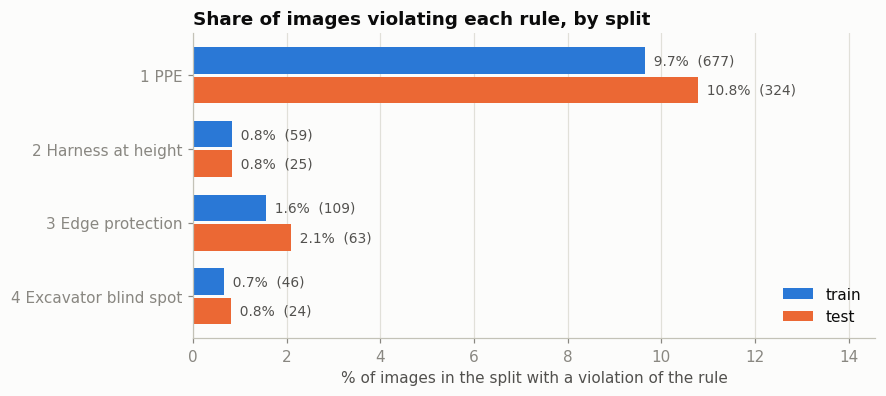

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(RULE_IDS))
h = 0.36
for i, s in enumerate(SPLITS[:2]):
    vals = violations[f"{s} %"].values
    counts = violations[f"{s} images"].values
    pos = y + (i - 0.5) * (h + 0.04)
    ax.barh(pos, vals, height=h, color=SPLIT_COLOR.get(s, "#1baf7a"), label=s)
    for p, v, c in zip(pos, vals, counts):
        ax.text(v, p, f"  {v:.1f}%  ({c})", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, [f"{k} {RULE_NAMES[k]}" for k in RULE_IDS])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlim(0, violations[[f"{s} %" for s in SPLITS[:2]]].values.max() * 1.35)
ax.set_xlabel("% of images in the split with a violation of the rule")
ax.set_title("Share of images violating each rule, by split")
ax.legend(frameon=False, loc="lower right")
save(fig, "violations_per_rule")
plt.show()

## 3. Class imbalance

How many images have no violation at all, and how many break more than one rule.
This matters for training (very few positive examples) and for reading the
metrics (accuracy is meaningless when almost every answer is "no").

In [10]:
imb = df.groupby("split")["any_violation"].agg(images="size", with_violation="sum").reindex(SPLITS)
imb["without_violation"] = imb["images"] - imb["with_violation"]
imb["% with violation"] = (imb["with_violation"] / imb["images"] * 100).round(2)
imb

,images,with_violation,without_violation,% with violation
split,,,,
train,7009,866,6143,12.36
test,3004,412,2592,13.72


In [11]:
n_rules = pd.crosstab(df["n_rules_violated"], df["split"])[SPLITS]
n_rules.index.name = "rules violated in the image"
n_rules

split,train,test
rules violated in the image,,
0,6143,2592
1,841,390
2,25,20
3,0,2


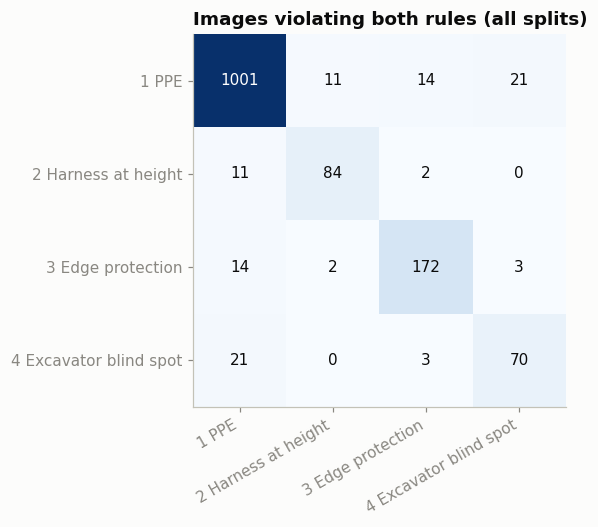

,1 PPE,2 Harness at height,3 Edge protection,4 Excavator blind spot
1 PPE,1001,11,14,21
2 Harness at height,11,84,2,0
3 Edge protection,14,2,172,3
4 Excavator blind spot,21,0,3,70


In [12]:
# Co-occurrence: cell (a, b) = images that violate both rule a and rule b.
# The diagonal is the total for that rule.
M = df[RULE_COLS].astype(int)
co = M.T @ M
labels = [f"{k} {RULE_NAMES[k]}" for k in RULE_IDS]
co.index = co.columns = labels
co.to_csv(OUT / "rule_cooccurrence.csv")

fig, ax = plt.subplots(figsize=(5.6, 4.4))
im = ax.imshow(co.values, cmap="Blues")
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
half = co.values.max() / 2
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, int(co.values[i, j]), ha="center", va="center",
                color="white" if co.values[i, j] > half else INK)
ax.set_title("Images violating both rules (all splits)")
save(fig, "rule_cooccurrence")
plt.show()
co

## 4. Image attributes

Each image is tagged with illumination, camera distance, view and quality of
info. The tables show how many images have each value, and how often a
violation appears for that value.

In [13]:
attr_tables = {}
for a in ATTRIBUTES:
    t = pd.crosstab(df[a].fillna("(missing)"), df["split"])[SPLITS]
    t["total"] = t.sum(axis=1)
    t["% of all images"] = (t["total"] / len(df) * 100).round(1)
    rate = df.assign(_a=df[a].fillna("(missing)")).groupby("_a")["any_violation"].mean() * 100
    t["% with any violation"] = rate.round(1)
    t = t.sort_values("total", ascending=False)
    t.index.name = a
    attr_tables[a] = t
    t.to_csv(OUT / f"attribute_{a}.csv")
    display(t)

split,train,test,total,% of all images,% with any violation
illumination,,,,,
normal lighting,5885,2426,8311,83.0,11.6
underexposed,692,381,1073,10.7,13.4
overexposed,273,154,427,4.3,12.2
night,159,43,202,2.0,56.9


split,train,test,total,% of all images,% with any violation
camera_distance,,,,,
mid distance,5063,1309,6372,63.6,13.1
short distance,1560,1360,2920,29.2,13.2
long distance,386,334,720,7.2,8.2
(missing),0,1,1,0.0,0.0


split,train,test,total,% of all images,% with any violation
view,,,,,
elevation view,6286,2895,9181,91.7,13.5
plan view,723,109,832,8.3,4.8


split,train,test,total,% of all images,% with any violation
quality_of_info,,,,,
rich info,3980,1291,5271,52.6,14.6
poor info,3029,1713,4742,47.4,10.7


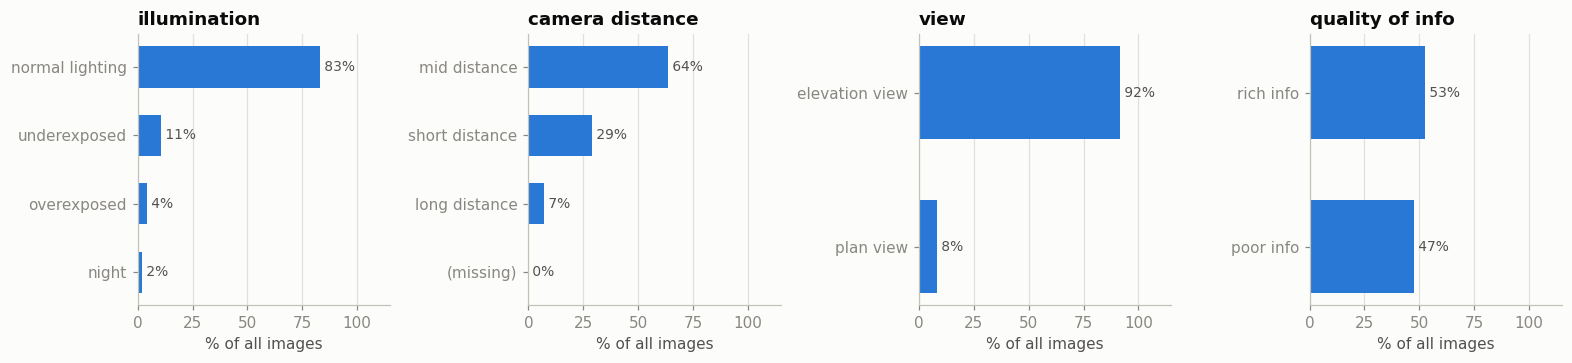

In [14]:
fig, axes = plt.subplots(1, len(ATTRIBUTES), figsize=(3.6 * len(ATTRIBUTES), 3.4))
for ax, a in zip(np.atleast_1d(axes), ATTRIBUTES):
    t = attr_tables[a].sort_values("total")
    ax.barh(t.index.astype(str), t["% of all images"], color=SPLIT_COLOR["train"], height=0.6)
    for yi, v in enumerate(t["% of all images"]):
        ax.text(v, yi, f" {v:.0f}%", va="center", fontsize=9, color="#52514e")
    ax.set_xlim(0, max(100, t["% of all images"].max()) * 1.15)
    ax.grid(axis="y", visible=False)
    ax.set_title(a.replace("_", " "))
    ax.set_xlabel("% of all images")
fig.tight_layout()
save(fig, "attributes")
plt.show()

## 5. Caption length

In [15]:
df["caption_words"] = df["caption"].str.split().str.len()
cap = df.groupby("split")["caption_words"].describe().reindex(SPLITS).round(1)
cap.loc["all"] = df["caption_words"].describe().round(1)
print("Images with an empty caption:", int((df["caption_words"] == 0).sum()))
cap

Images with an empty caption: 0


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,7009.0,55.0,15.2,12.0,45.0,54.0,64.0,134.0
test,3004.0,48.5,29.8,2.0,25.0,44.0,68.0,163.0
all,10013.0,53.1,20.9,2.0,40.0,53.0,65.0,163.0


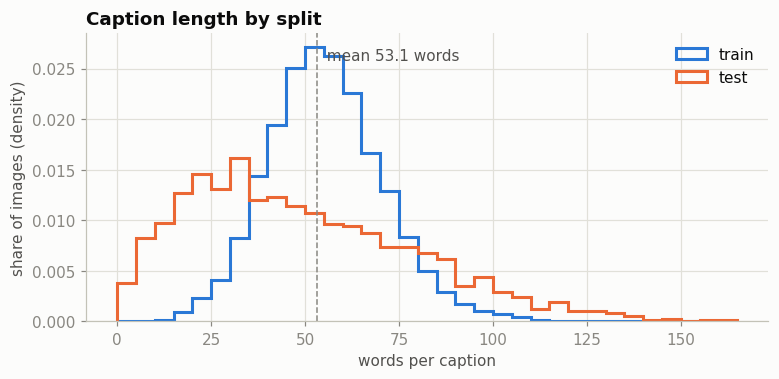

Example caption:

The image shows three workers with yellow hard hats, engaged in tasks related to reinforcing steel
bars at a construction site. One worker is bending over the rebar framework, while the other is
handling large curved segments of material. A yellow excavator is visible in the background on the
left, while the third worker is standing at the back of it.


In [16]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(0, df["caption_words"].max() + 5, 5)
for s in SPLITS[:2]:
    ax.hist(df.loc[df["split"] == s, "caption_words"], bins=bins, density=True,
            histtype="step", linewidth=2, color=SPLIT_COLOR.get(s), label=s)
mean = df["caption_words"].mean()
ax.axvline(mean, color=MUTED, linewidth=1, linestyle="--")
ax.text(mean, ax.get_ylim()[1] * 0.95, f"  mean {mean:.1f} words", color="#52514e", va="top")
ax.set_xlabel("words per caption")
ax.set_ylabel("share of images (density)")
ax.set_title("Caption length by split")
ax.legend(frameon=False)
save(fig, "caption_length")
plt.show()

print("Example caption:\n")
print(textwrap.fill(df.loc[df["caption_words"] > 0, "caption"].iloc[0], 100))

## 6. Image resolution

Reads only each picture's header (width and height), so the 10,013 images are
not fully decoded. Takes a minute or two.

In [17]:
size_rows = []
for split, d in ds.items():
    raw = d.select_columns(["image_id", "image"]).cast_column("image", HFImage(decode=False))
    for ex in raw:
        im = ex["image"]
        src = io.BytesIO(im["bytes"]) if im.get("bytes") else im["path"]
        with Image.open(src) as pic:
            w, h = pic.size
        size_rows.append((split, str(ex["image_id"]), w, h))
sizes = pd.DataFrame(size_rows, columns=["split", "image_id", "width", "height"])
df = df.drop(columns=[c for c in ["width", "height"] if c in df]).merge(sizes, on=["split", "image_id"], how="left")
df["megapixels"] = df["width"] * df["height"] / 1e6
df["aspect"] = df["width"] / df["height"]
df[["width", "height", "megapixels", "aspect"]].describe().round(2)

,width,height,megapixels,aspect
count,10013.00,10013.00,10013.00,10013.00
mean,1167.47,911.28,1.14,1.32
std,352.67,285.94,1.15,0.27
min,288.00,164.00,0.05,0.45
25%,1166.00,800.00,0.96,1.33
50%,1200.00,900.00,1.08,1.33
75%,1200.00,900.00,1.08,1.33
max,4912.00,4416.00,14.63,5.20


In [18]:
top_res = (df["width"].astype(str) + " x " + df["height"].astype(str)).value_counts().head(10)
top_res = top_res.rename("images").to_frame()
top_res["% of all images"] = (top_res["images"] / len(df) * 100).round(1)
top_res.index.name = "resolution (w x h)"
print("Portrait images (taller than wide):", int((df["aspect"] < 1).sum()))
top_res

Portrait images (taller than wide): 1054


,images,% of all images
resolution (w x h),,
1200 x 900,5376,53.7
1200 x 675,697,7.0
900 x 1200,571,5.7
1200 x 800,545,5.4
907 x 765,355,3.5
1000 x 1000,201,2.0
1280 x 960,179,1.8
720 x 540,155,1.5
1080 x 1440,138,1.4


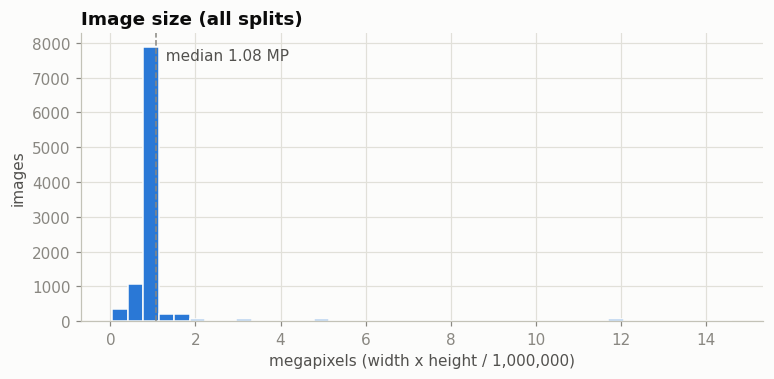

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(df["megapixels"], bins=40, color=SPLIT_COLOR["train"], edgecolor=SURFACE, linewidth=1)
med = df["megapixels"].median()
ax.axvline(med, color=MUTED, linewidth=1, linestyle="--")
ax.text(med, ax.get_ylim()[1] * 0.95, f"  median {med:.2f} MP", color="#52514e", va="top")
ax.set_xlabel("megapixels (width x height / 1,000,000)")
ax.set_ylabel("images")
ax.set_title("Image size (all splits)")
save(fig, "image_megapixels")
plt.show()

## 7. Bounding boxes

Two kinds of boxes: boxes around each **violation**, and boxes for the three
**grounding objects** (excavator, rebar, worker with white hard hat). The
dataset card says coordinates are `[x1, y1, x2, y2]`, normalised to 0-1.

In [20]:
print("Largest coordinate value in the data:", boxes[["x1", "y1", "x2", "y2"]].max().max() if len(boxes) else "no boxes")
boxes["w"] = boxes["x2"] - boxes["x1"]
boxes["h"] = boxes["y2"] - boxes["y1"]
boxes["area"] = boxes["w"] * boxes["h"]   # fraction of the image if coordinates are 0-1

name = {f"rule_{k}": f"rule {k} {RULE_NAMES[k]}" for k in RULE_IDS}
box_summary = boxes.groupby(["kind", "label"]).agg(
    boxes=("area", "size"),
    images=("image_id", "nunique"),
    median_area=("area", "median"),
    mean_area=("area", "mean"),
).round(4)
box_summary["boxes per image"] = (box_summary["boxes"] / box_summary["images"]).round(2)
box_summary = box_summary.rename(index=name, level="label")
box_summary.to_csv(OUT / "box_summary.csv")
box_summary

Largest coordinate value in the data: 1.0


boxes  images  median_area  mean_area  \
kind      label                                                                
object    excavator                     4681    3495       0.0696     0.1430   
          rebar                         2978    1173       0.0207     0.0442   
          worker_with_white_hard_hat    1401     994       0.0168     0.0490   
violation rule 1 PPE                    1662     999       0.0136     0.0387   
          rule 2 Harness at height       146      84       0.0084     0.0172   
          rule 3 Edge protection         199     172       0.1638     0.2004   
          rule 4 Excavator blind spot     71      70       0.0102     0.0189   

                                       boxes per image  
kind      label                                         
object    excavator                               1.34  
          rebar                                   2.54  
          worker_with_white_hard_hat              1.41  
violation rule 1 PPE                              1.66  
          rule 2 Harness at height                1.74  
          rule 3 Edge protection                  1.16  
          rule 4 Excavator blind spot             1.01

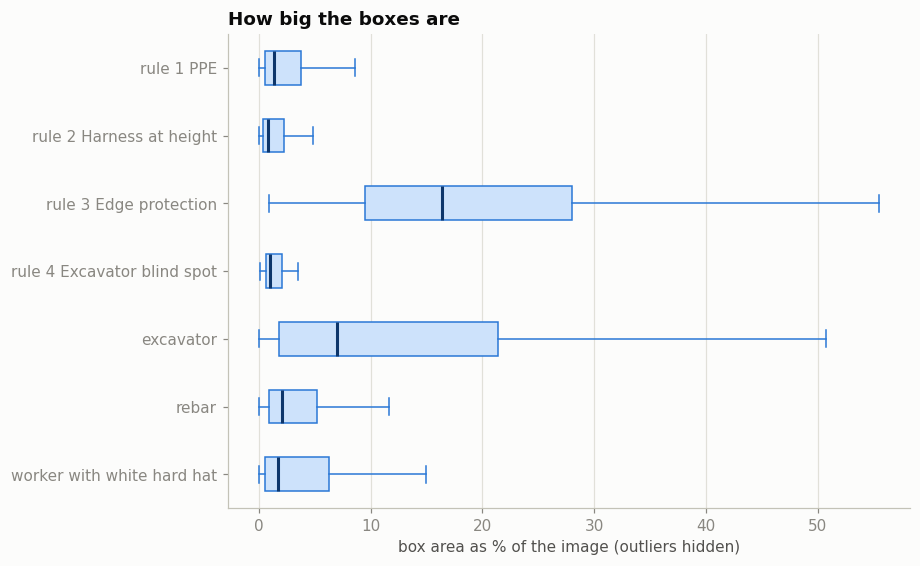

In [21]:
order = [l for l in list(name) + GROUNDING if l in set(boxes["label"])]
if order:
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(order) + 1.4))
    data = [boxes.loc[boxes["label"] == l, "area"].clip(0, 1).values * 100 for l in order]
    import matplotlib
    horiz = ({"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10)
             else {"vert": False})
    ax.boxplot(data, widths=0.5, showfliers=False, patch_artist=True, **horiz,
               boxprops=dict(facecolor="#cde2fb", edgecolor=SPLIT_COLOR["train"]),
               medianprops=dict(color="#0d366b", linewidth=2),
               whiskerprops=dict(color=SPLIT_COLOR["train"]), capprops=dict(color=SPLIT_COLOR["train"]))
    ax.set_yticks(range(1, len(order) + 1), [name.get(l, l.replace("_", " ")) for l in order])
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("box area as % of the image (outliers hidden)")
    ax.set_title("How big the boxes are")
    save(fig, "box_area")
    plt.show()

In [22]:
# Grounding objects: how many images contain each one.
g = pd.DataFrame({
    "images with object": [(df[f"n_{x}"] > 0).sum() for x in GROUNDING],
    "% of all images": [round((df[f"n_{x}"] > 0).mean() * 100, 1) for x in GROUNDING],
    "total boxes": [df[f"n_{x}"].sum() for x in GROUNDING],
    "max in one image": [df[f"n_{x}"].max() for x in GROUNDING],
}, index=GROUNDING)
g

,images with object,% of all images,total boxes,max in one image
excavator,3495,34.9,4681,6
rebar,1173,11.7,2978,23
worker_with_white_hard_hat,994,9.9,1401,9


## 8. Violation reasons

Each violation comes with a short reason written by the annotators. These are
the texts a fine-tuned model would learn to produce.

In [23]:
STOP = set("""a an the of in on at to and or is are was were be been being with without for from by as it its this
that there their they he she his her not no any some which who while when where into over under near than then
also has have had do does did but if so such can will would may might could should one two""".split())

recs = []
for k in RULE_IDS:
    r = df.loc[df[f"rule_{k}"], f"rule_{k}_reason"]
    r = r[r.str.strip() != ""]
    words = Counter(w for t in r for w in re.findall(r"[a-z']+", t.lower()) if w not in STOP and len(w) > 2)
    recs.append({
        "rule": f"{k} {RULE_NAMES[k]}",
        "reasons": len(r),
        "mean words": round(r.str.split().str.len().mean(), 1) if len(r) else None,
        "max words": int(r.str.split().str.len().max()) if len(r) else None,
        "most common words": ", ".join(w for w, _ in words.most_common(12)),
    })
pd.DataFrame(recs).set_index("rule")

,reasons,mean words,max words,most common words
rule,,,,
1 PPE,1000,12.4,35,"wearing, hard, hat, worker, workers, hats, left, middle, right, visibility, high, person"
2 Harness at height,84,12.7,20,"safety, wearing, workers, harnesses, harness, worker, scaffolding, top, standing, scaffold, left, right"
3 Edge protection,172,10.1,17,"edge, excavation, guarded, right, protected, warned, concrete, nor, left, platform, middle, edges"
4 Excavator blind spot,70,17.1,24,"excavator, worker, spot, blind, operation, radius, left, close, within, hard, hat, middle"


In [24]:
for k in RULE_IDS:
    r = df.loc[df[f"rule_{k}"] & (df["split"] == "train") & (df[f"rule_{k}_reason"].str.strip() != ""), f"rule_{k}_reason"]
    print(f"Rule {k} ({RULE_NAMES[k]}), {len(r)} train reasons. Examples:")
    for t in r.head(4):
        print(textwrap.fill(t, 100, initial_indent="   - ", subsequent_indent="     "))
    print()

Rule 1 (PPE), 676 train reasons. Examples:
   - The worker with a red hard hat in the middle does not have long pants.
   - The worker in the middle does not have a hard hat.
   - The two workers do not have high-visibility retroreflective vests when working at night.
   - The worker in the lower right corner does not have a hard hat.

Rule 2 (Harness at height), 59 train reasons. Examples:
   - Workers on the scaffold on the left are not wearing safety harnesses.
   - The worker on the scaffolding is not wearing a safety harness.
   - The workers on the scaffolding are not wearing safety harnesses.
   - Three workers on the rooftop are not wearing safety harnesses.

Rule 3 (Edge protection), 109 train reasons. Examples:
   - The excavation edge in the background is not protected.
   - The edge of the excavation is not guarded.
   - The edge of the excavation is not protected.
   - The left edge of the excavation is not guarded.

Rule 4 (Excavator blind spot), 46 train reasons. Example

## 9. Data-quality checks

Looks for anything that would quietly distort training or evaluation.

In [25]:
checks = {}

# 1. Duplicate ids
checks["duplicate image_id within a split"] = int(df.duplicated(["split", "image_id"]).sum())
ids = {s: set(df.loc[df["split"] == s, "image_id"]) for s in SPLITS}
checks["image_id present in both train and test"] = len(ids.get("train", set()) & ids.get("test", set()))

# 2. Missing fields
checks["empty captions"] = int((df["caption"].str.strip() == "").sum())
for a in ATTRIBUTES:
    checks[f"missing {a}"] = int(df[a].isna().sum())

# 3. Incomplete violation annotations (a reason without a box, or a box without a reason)
incomplete = []
for k in RULE_IDS:
    has_box = df[f"rule_{k}_boxes"] > 0
    has_reason = df[f"rule_{k}_reason"].str.strip() != ""
    bad = df[has_box ^ has_reason]
    for _, r in bad.iterrows():
        incomplete.append({"split": r["split"], "image_id": r["image_id"], "rule": k,
                           "boxes": r[f"rule_{k}_boxes"], "reason": r[f"rule_{k}_reason"]})
incomplete = pd.DataFrame(incomplete, columns=["split", "image_id", "rule", "boxes", "reason"])
checks["violation annotations with a reason but no box, or a box but no reason"] = len(incomplete)

# 4. Bad boxes
if len(boxes):
    coords = boxes[["x1", "y1", "x2", "y2"]]
    checks["boxes with zero or negative width/height"] = int(((boxes["w"] <= 0) | (boxes["h"] <= 0)).sum())
    checks["boxes with a coordinate outside 0-1"] = int(((coords < 0) | (coords > 1)).any(axis=1).sum())

quality = pd.Series(checks, name="count").to_frame()
quality.to_csv(OUT / "quality_checks.csv")
quality

,count
duplicate image_id within a split,0
image_id present in both train and test,0
empty captions,0
missing illumination,0
missing camera_distance,1
missing view,0
missing quality_of_info,0
"violation annotations with a reason but no box, or a box but no reason",3
boxes with zero or negative width/height,4
boxes with a coordinate outside 0-1,0


In [26]:
# Any incomplete annotations are listed here. These are the candidates for the
# one-image difference from the paper's count (test, rule 1: 324 in the data vs 323).
incomplete if len(incomplete) else print("No incomplete violation annotations.")

,split,image_id,rule,boxes,reason
0,train,0009782,1,0,The worker squatting on the left is not wearing a hard hat.
1,train,0013097,1,1,
2,test,0000167,1,0,The two workers on the right are too close to the arm of the excavator.


## 10. Example images

Three **train** images per rule, with the violation boxes drawn and the
annotator's reason underneath. (Train only: looking closely at test examples
while designing prompts or models would make the test score unfair.)

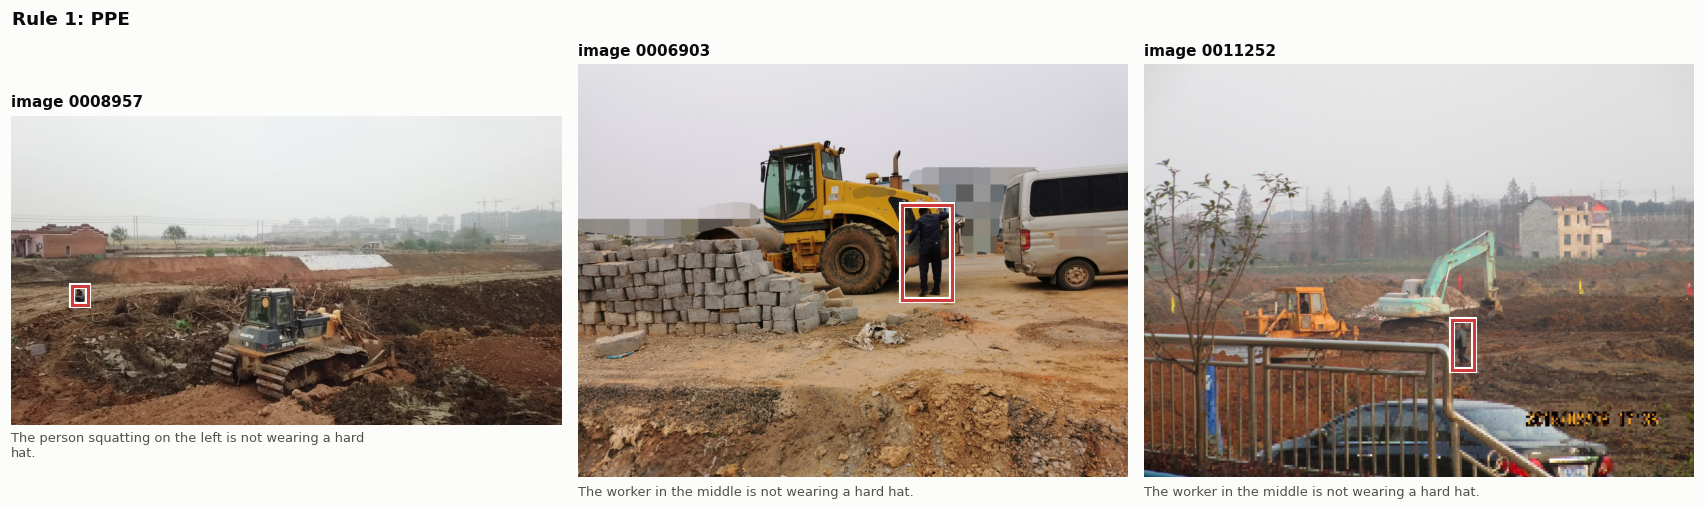

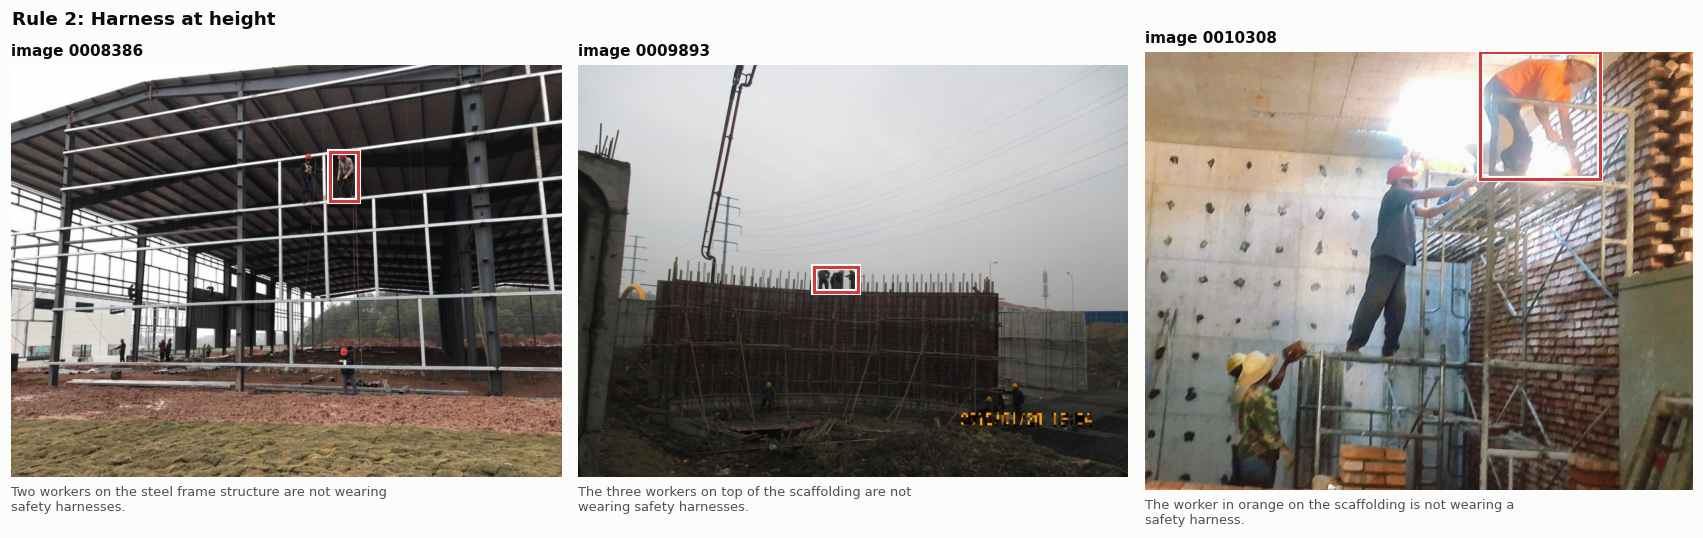

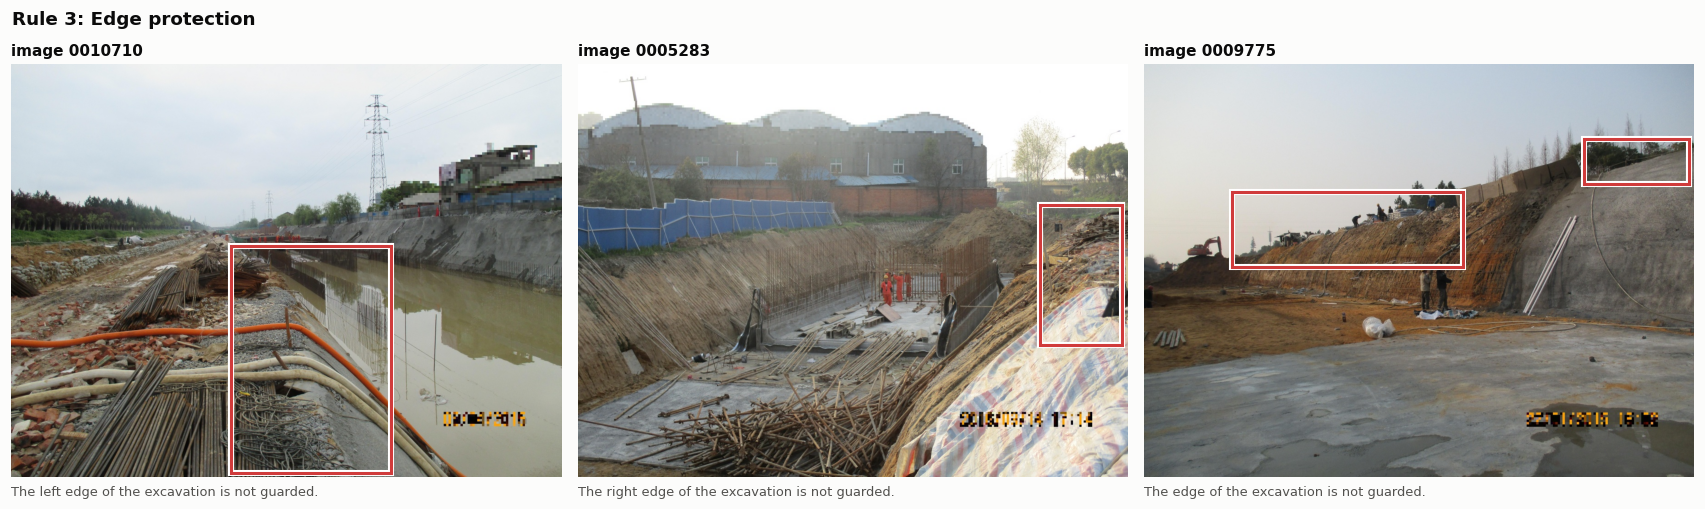

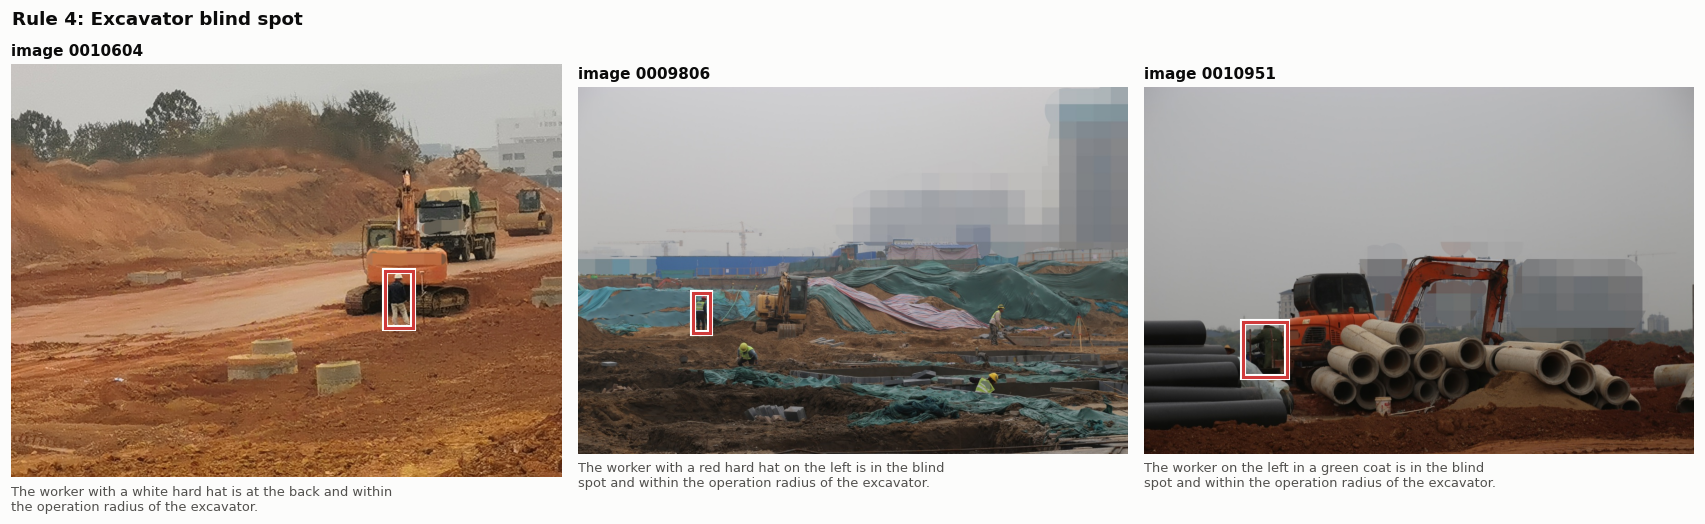

In [27]:
def show_examples(rule_id, n=3, split="train", seed=0):
    sub = df[(df["split"] == split) & df[f"rule_{rule_id}"]]
    if sub.empty:
        print(f"No {split} images violate rule {rule_id}.")
        return
    sub = sub.sample(min(n, len(sub)), random_state=seed)
    fig, axes = plt.subplots(1, len(sub), figsize=(5.2 * len(sub), 4.6))
    for ax, (_, r) in zip(np.atleast_1d(axes), sub.iterrows()):
        ex = ds[split][int(r["idx"])]
        img = ex["image"].convert("RGB")
        W, H = img.size
        ax.imshow(img)
        for x1, y1, x2, y2 in boxes_of(ex.get(f"rule_{rule_id}_violation")):
            if max(x1, y1, x2, y2) <= 1.0:   # normalised coordinates
                x1, x2, y1, y2 = x1 * W, x2 * W, y1 * H, y2 * H
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="white", linewidth=4))
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="#d03b3b", linewidth=2))
        ax.set_axis_off()
        ax.set_title(f"image {r['image_id']}", fontsize=10)
        ax.text(0, -0.02, textwrap.fill(r[f"rule_{rule_id}_reason"], 58), transform=ax.transAxes,
                va="top", fontsize=8.5, color="#52514e")
    fig.suptitle(f"Rule {rule_id}: {RULE_NAMES[rule_id]}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save(fig, f"examples_rule_{rule_id}")
    plt.show()


for k in RULE_IDS:
    show_examples(k)

## Save the tables

In [28]:
keep = [c for c in df.columns if c != "idx"]
df[keep].to_csv(OUT / "metadata.csv", index=False)
boxes.to_csv(OUT / "boxes.csv", index=False)
print("Saved to", OUT)
for p in sorted(OUT.iterdir()):
    print("  ", p.name)

Saved to e:\Mayank\Nirma\Projects\construction-safety-vlm\outputs\eda
   attribute_camera_distance.csv
   attribute_illumination.csv
   attribute_quality_of_info.csv
   attribute_view.csv
   attributes.png
   box_area.png
   box_summary.csv
   boxes.csv
   caption_length.png
   examples_rule_1.png
   examples_rule_2.png
   examples_rule_3.png
   examples_rule_4.png
   image_megapixels.png
   metadata.csv
   quality_checks.csv
   rule_cooccurrence.csv
   rule_cooccurrence.png
   violations_per_rule.csv
   violations_per_rule.png


## What to take from this

Fill this in from the numbers above once the notebook has run on the real data:

- Share of images with any violation, per split:
- Rarest rule and its train count (this limits fine-tuning for that rule):
- Typical image size, and what `--max-pixels` that suggests:
- Typical violation box size (small boxes mean the model needs enough resolution):
- Any data-quality issues found in section 9: